In [29]:
#Importing relevant libraries
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors
from rdkit.Chem import PandasTools

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
sns.set_palette("husl")

from data_profiling import ProfileReport   

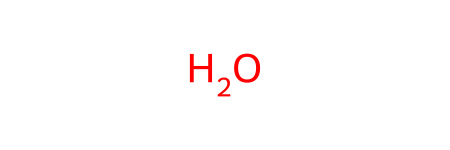

In [3]:
water = Chem.MolFromSmiles('O')
water

In [7]:
#Loading the dataset
url = "https://raw.githubusercontent.com/Natashasia/CHE1147-Group-6/main/raw_data_tox21.csv"
df = pd.read_csv(url)

#Checking the dataset
df.head()

,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O


In [12]:
#Checking for any duplicate molecules in the dataset
unique_smiles = df['smiles'].nunique()
num_smiles = df['smiles'].shape[0]
print(f'Unique SMILES: {unique_smiles}')
print(f'Total SMILES: {num_smiles}')

Unique SMILES: 7831
Total SMILES: 7831


In [14]:
#Declare a function for canonicalizing isomeric SMILES
def con_smiles(smile, isomeric:bool=True):
    mol = Chem.MolFromSmiles(smile)
    canonical_smiles = Chem.MolToSmiles(mol, isomericSmiles=isomeric)
    return canonical_smiles

In [18]:
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='smiles', molCol = 'molecule')
df.head()

[10:26:11] WARNING: not removing hydrogen atom without neighbors
[10:26:11] Explicit valence for atom # 8 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 3 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 4 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 4 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 9 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 5 Al, 6, is greater than permitted
[10:26:12] Explicit valence for atom # 16 Al, 6, is greater than permitted
[10:26:12] Explicit valence for atom # 20 Al, 6, is greater than permitted


,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles,molecule
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...


In [20]:
#Create and use a function to apply key molecular descriptors to the dataset
def calculate_key_descriptors(mol):
    descriptors = {
        'MolWt': Descriptors.MolWt(mol),
        'LogP' : Descriptors.MolLogP(mol),
        'TPSA': Descriptors.TPSA(mol),
        'NumHDonors': Descriptors.NumHDonors(mol),
        'NumHAcceptors': Descriptors.NumHAcceptors(mol),
        'RotBonds' : Descriptors.NumRotatableBonds(mol)
    }
    return descriptors

descriptor_data = []
for row, mol in df['molecule'].items():
    if mol is None:
        desc = {
            'MolWt': np.nan,
            'LogP': np.nan,
            'TPSA': np.nan,
            'NumHDonors': np.nan,
            'NumHAcceptors': np.nan,
            'RotBonds': np.nan
        }
    else:
        desc = calculate_key_descriptors(mol)
    descriptor_data.append(desc)

descriptor_df = pd.DataFrame(descriptor_data, index=df.index)

df_with_descriptors = pd.concat([df, descriptor_df], axis=1)

df_with_descriptors.head()

,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,...,SR-p53,mol_id,smiles,molecule,MolWt,LogP,TPSA,NumHDonors,NumHAcceptors,RotBonds
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,...,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...,258.324,1.34240,82.28,1.0,5.0,3.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,...,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...,204.229,1.29940,49.41,1.0,2.0,2.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,...,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...,288.475,5.09030,20.23,1.0,1.0,1.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,...,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...,276.424,3.75244,32.34,1.0,2.0,7.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...,206.027,-0.99220,135.29,5.0,3.0,2.0


In [22]:
df_with_descriptors.info()
df_with_descriptors.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7831 entries, 0 to 7830
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   NR-AR          7265 non-null   float64
 1   NR-AR-LBD      6758 non-null   float64
 2   NR-AhR         6549 non-null   float64
 3   NR-Aromatase   5821 non-null   float64
 4   NR-ER          6193 non-null   float64
 5   NR-ER-LBD      6955 non-null   float64
 6   NR-PPAR-gamma  6450 non-null   float64
 7   SR-ARE         5832 non-null   float64
 8   SR-ATAD5       7072 non-null   float64
 9   SR-HSE         6467 non-null   float64
 10  SR-MMP         5810 non-null   float64
 11  SR-p53         6774 non-null   float64
 12  mol_id         7831 non-null   object 
 13  smiles         7831 non-null   object 
 14  molecule       7823 non-null   object 
 15  MolWt          7823 non-null   float64
 16  LogP           7823 non-null   float64
 17  TPSA           7823 non-null   float64
 18  NumHDono

,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,MolWt,LogP,TPSA,NumHDonors,NumHAcceptors,RotBonds
count,7265.000000,6758.000000,6549.000000,5821.000000,6193.000000,6955.000000,6450.000000,5832.000000,7072.000000,6467.000000,5810.000000,6774.000000,7823.000000,7823.000000,7823.000000,7823.000000,7823.000000,7823.000000
mean,0.042533,0.035070,0.117270,0.051538,0.128048,0.050324,0.028837,0.161523,0.037330,0.057523,0.158003,0.062445,276.144155,2.373943,59.472201,1.224978,3.473987,4.302697
std,0.201815,0.183969,0.321766,0.221110,0.334170,0.218627,0.167362,0.368044,0.189583,0.232857,0.364776,0.241979,164.732356,2.304307,57.794990,1.916035,3.115448,4.464772
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.012000,-17.406400,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,165.236000,1.149350,26.300000,0.000000,2.000000,1.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.302000,2.365500,46.530000,1.000000,3.000000,3.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,343.044000,3.653150,77.030000,2.000000,4.000000,6.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1877.664000,22.611800,777.980000,30.000000,46.000000,47.000000


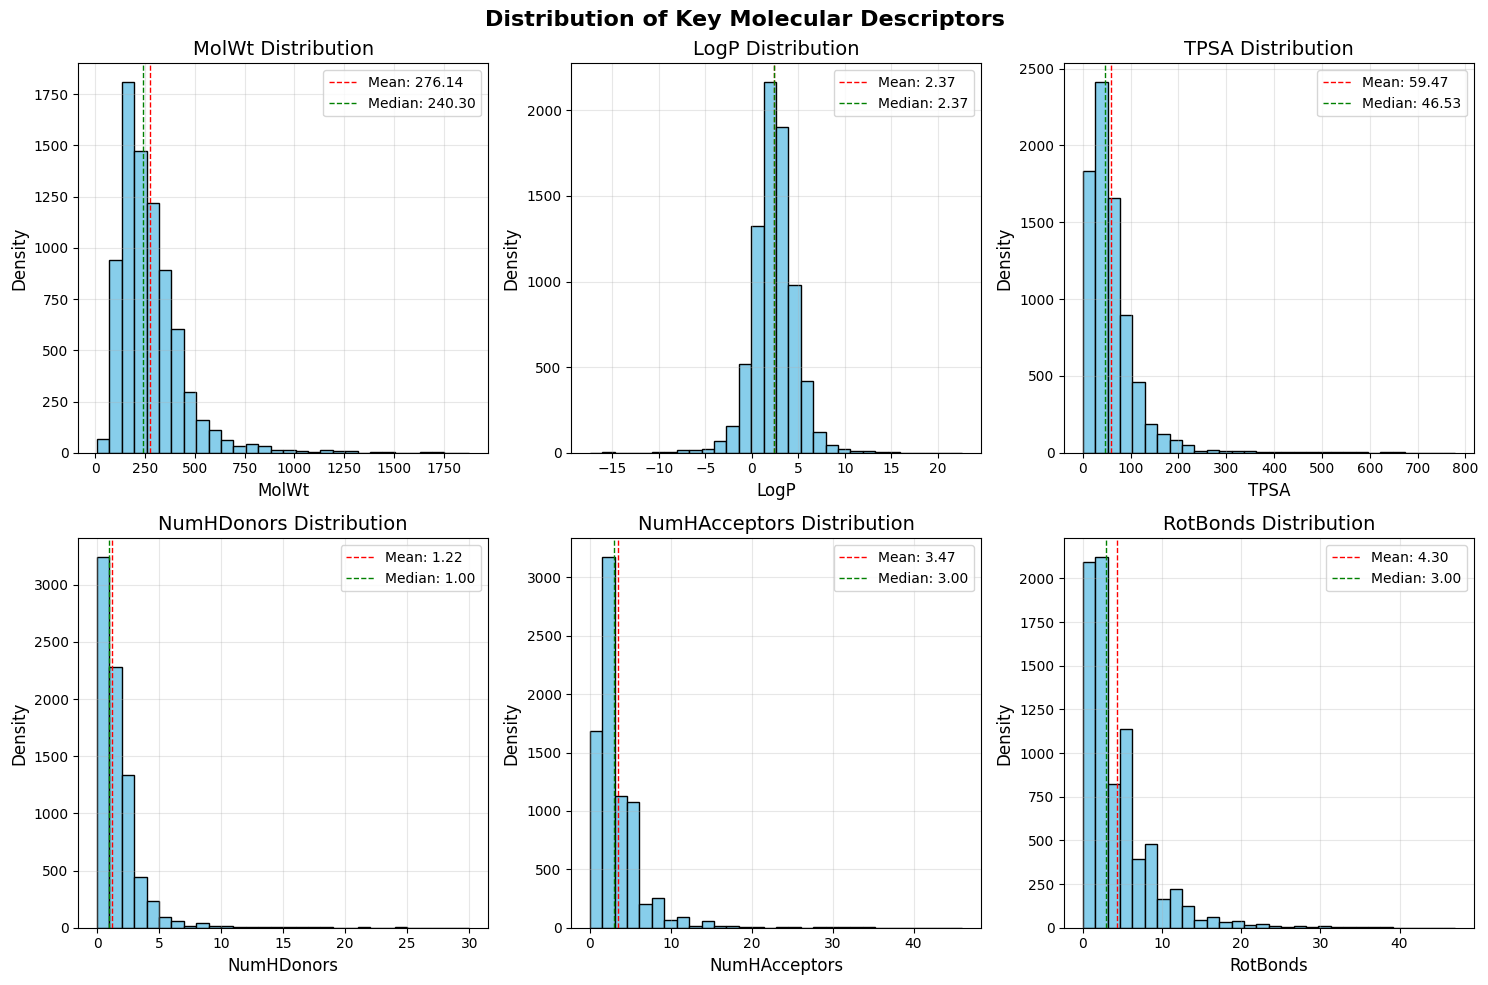

In [ ]:
#Plotting key features of the dataset
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Distribution of Key Molecular Descriptors', fontsize=16, fontweight='bold')

descriptors_to_plot = ['MolWt', 'LogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'RotBonds']

for i, descriptor in enumerate(descriptors_to_plot):
    row = i // 3
    col = i % 3

    axes[row, col].hist(df_with_descriptors[descriptor].dropna(), bins=30, color='skyblue', edgecolor='black')

    mean_val = df_with_descriptors[descriptor].mean()
    median_val = df_with_descriptors[descriptor].median()
    axes[row, col].axvline(mean_val, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_val:.2f}')
    axes[row, col].axvline(median_val, color='green', linestyle='dashed', linewidth=1, label=f'Median: {median_val:.2f}')
    axes[row, col].set_title(f'{descriptor} Distribution', fontsize=14)
    axes[row, col].set_xlabel(descriptor, fontsize=12)
    axes[row, col].set_ylabel('Density', fontsize=12)
    axes[row, col].legend()
    axes[row, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
#Determining Descriptor Correlations
descriptor_columns = ['MolWt', 'LogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'RotBonds']
correlation_matrix = df_with_descriptors[descriptor_columns].corr()

correlation_matrix

,MolWt,LogP,TPSA,NumHDonors,NumHAcceptors,RotBonds
MolWt,1.000000,0.275194,0.695444,0.514816,0.744040,0.607598
LogP,0.275194,1.000000,-0.375008,-0.422518,-0.262644,0.299466
TPSA,0.695444,-0.375008,1.000000,0.828390,0.910737,0.406456
NumHDonors,0.514816,-0.422518,0.828390,1.000000,0.674845,0.282110
NumHAcceptors,0.744040,-0.262644,0.910737,0.674845,1.000000,0.453912
RotBonds,0.607598,0.299466,0.406456,0.282110,0.453912,1.000000


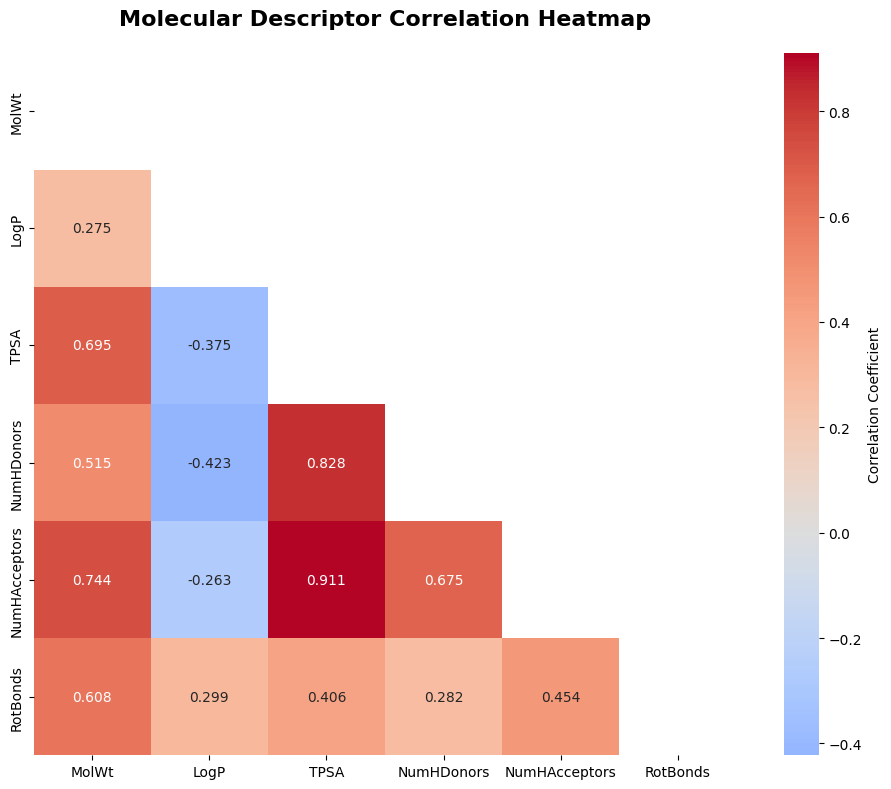

In [26]:
#Ploting a correlation heatmap
plt.figure(figsize=(10, 8))

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True,cmap='coolwarm', center=0, square=True,fmt='.3f',cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Molecular Descriptor Correlation Heatmap', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [ ]:
#Generate a report profile
profile = ProfileReport(df_with_descriptors, title="Tox21 Dataset EDA Report", explorative=True)

In [31]:
#Display profile generated report
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 46.81it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [32]:
profile.to_file("tox21_eda_report.html")

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]